# Customer Churn Prediction

**Internship Task 3: Machine Learning**

**Objective:** Build a model that predicts whether a bank customer will leave (churn), using historical customer data such as demographics and account behaviour. Logistic Regression, Random Forest and Gradient Boosting are compared.

**Dataset:** `Churn_Modelling.csv` (10,000 customers, target column `Exited`: 1 = churned, 0 = stayed)

**Workflow**

1. Load and understand the data
2. Clean the data
3. Exploratory data analysis
4. Preprocessing and train/test split
5. Train and compare three models
6. Cross-validation and hyperparameter tuning
7. Final evaluation and decision threshold
8. Feature importance
9. Save the model and predict for a new customer

## 1. Import Libraries

In [1]:
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_val_predict,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)

RANDOM_STATE = 42

## 2. Load the Data

In [2]:
df = pd.read_csv("Churn_Modelling.csv")
print("Shape:", df.shape)
df.head()

Shape: (10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.000,1,1,1,101348.880,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.860,1,0,1,112542.580,0
2,3,15619304,Onio,502,France,Female,42,8,159660.800,3,1,0,113931.570,1
3,4,15701354,Boni,699,France,Female,39,1,0.000,2,0,0,93826.630,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.820,1,1,1,79084.100,0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
RowNumber,10000.000,5000.500,2886.896,1.000,2500.750,5000.500,7500.250,10000.000
CustomerId,10000.000,15690940.569,71936.186,15565701.000,15628528.250,15690738.000,15753233.750,15815690.000
CreditScore,10000.000,650.529,96.653,350.000,584.000,652.000,718.000,850.000
Age,10000.000,38.922,10.488,18.000,32.000,37.000,44.000,92.000
Tenure,10000.000,5.013,2.892,0.000,3.000,5.000,7.000,10.000
Balance,10000.000,76485.889,62397.405,0.000,0.000,97198.540,127644.240,250898.090
NumOfProducts,10000.000,1.530,0.582,1.000,1.000,1.000,2.000,4.000
HasCrCard,10000.000,0.706,0.456,0.000,0.000,1.000,1.000,1.000
IsActiveMember,10000.000,0.515,0.500,0.000,0.000,1.000,1.000,1.000
EstimatedSalary,10000.000,100090.240,57510.493,11.580,51002.110,100193.915,149388.247,199992.480


## 3. Data Cleaning

`RowNumber`, `CustomerId` and `Surname` are identifiers. They carry no information about a customer's behaviour, so they are removed before modelling.

In [5]:
df = df.drop(columns=["RowNumber", "CustomerId", "Surname"])

print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("Remaining columns:", list(df.columns))

Missing values: 0
Duplicate rows: 0
Remaining columns: ['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']


## 4. Exploratory Data Analysis

### 4.1 Target distribution

,Customers,Share
Stayed (0),7963,0.796
Churned (1),2037,0.204


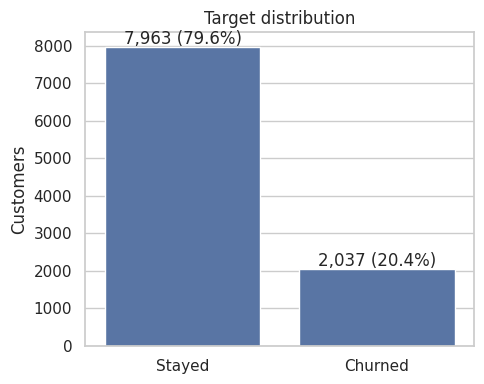

In [6]:
counts = df["Exited"].value_counts().sort_index()
rates = df["Exited"].value_counts(normalize=True).sort_index()

summary = pd.DataFrame(
    {"Customers": counts.values, "Share": rates.values},
    index=["Stayed (0)", "Churned (1)"],
)
display(summary)

fig, ax = plt.subplots(figsize=(5, 4))
sns.barplot(x=["Stayed", "Churned"], y=counts.values, ax=ax)
ax.set_ylabel("Customers")
ax.set_title("Target distribution")
for i, v in enumerate(counts.values):
    ax.text(i, v + 100, f"{v:,} ({rates.values[i]:.1%})", ha="center")
plt.tight_layout()
plt.show()

Only about one customer in five churns, so the classes are imbalanced. A model that always predicts "stayed" would score about 80% accuracy while catching no churners, so **accuracy alone is not enough**. Recall, F1-score and ROC-AUC are tracked as well.

### 4.2 Churn rate by customer segment

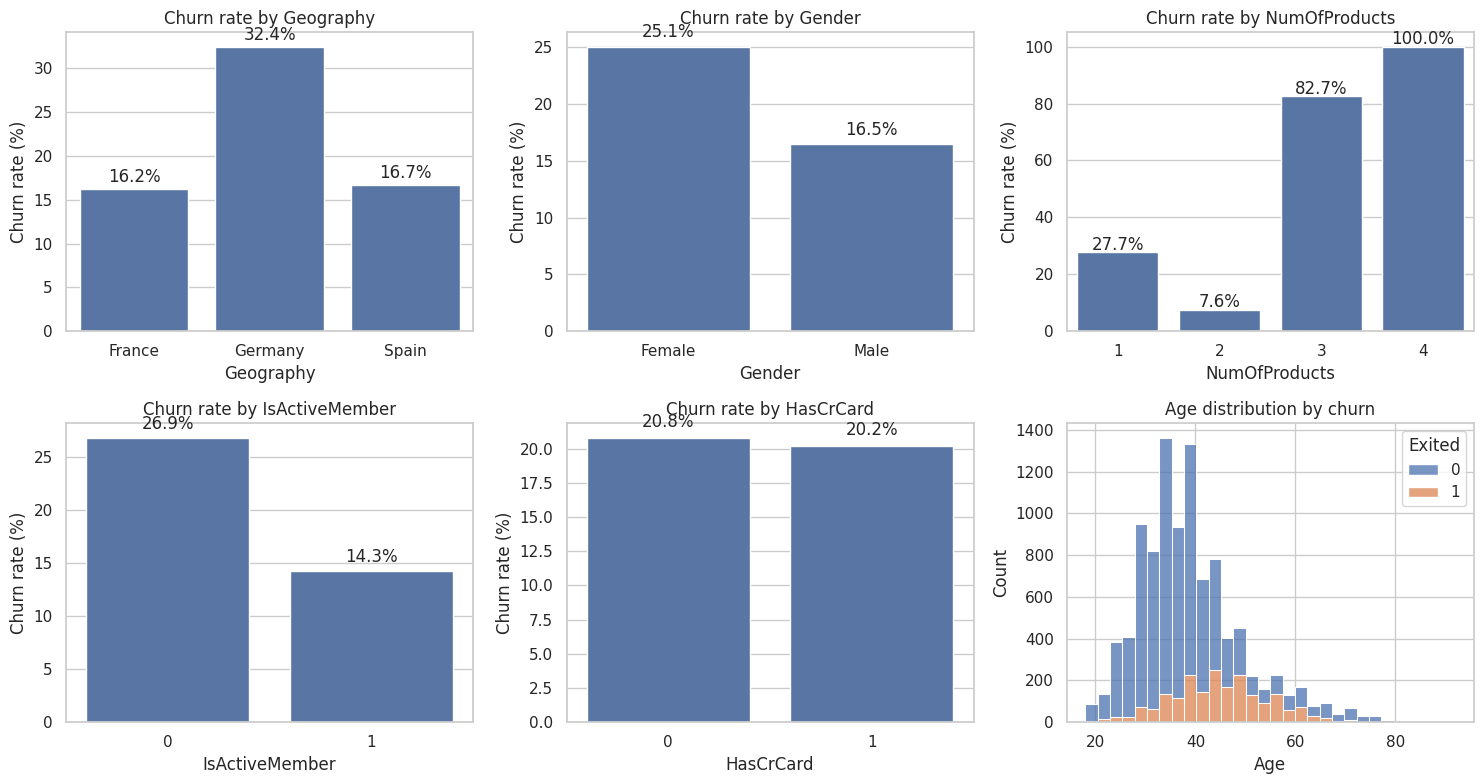

In [7]:
segments = ["Geography", "Gender", "NumOfProducts", "IsActiveMember", "HasCrCard"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()

for ax, col in zip(axes, segments):
    rate = df.groupby(col)["Exited"].mean().mul(100)
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax)
    ax.set_title(f"Churn rate by {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Churn rate (%)")
    for i, v in enumerate(rate.values):
        ax.text(i, v + 0.8, f"{v:.1f}%", ha="center")

sns.histplot(data=df, x="Age", hue="Exited", bins=30, multiple="stack", ax=axes[5])
axes[5].set_title("Age distribution by churn")

plt.tight_layout()
plt.show()

### 4.3 Numeric features by churn status

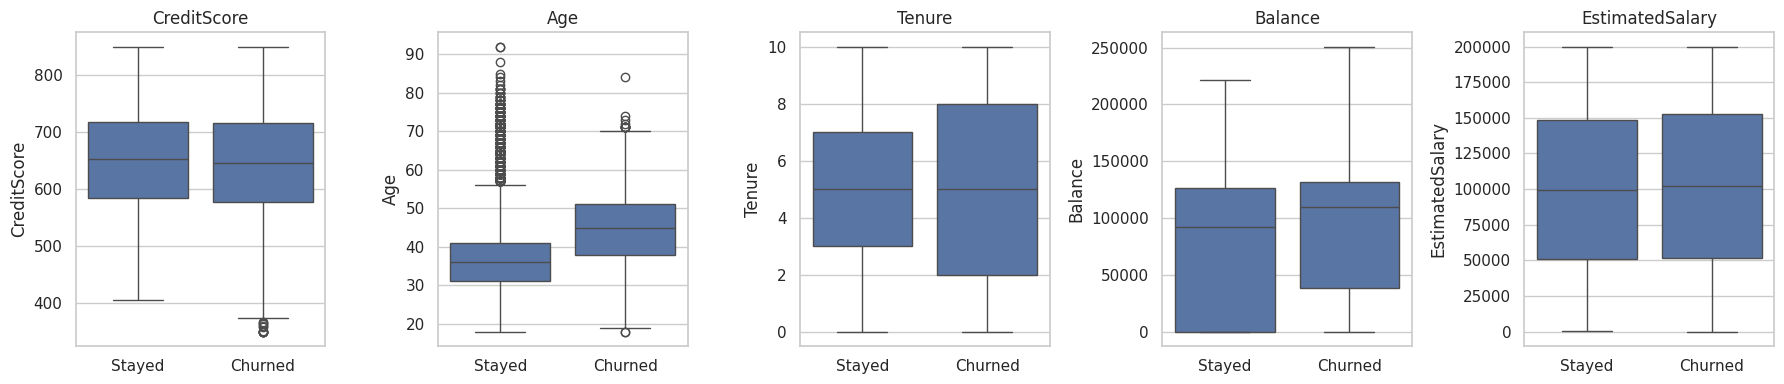

In [8]:
numeric_view = ["CreditScore", "Age", "Tenure", "Balance", "EstimatedSalary"]

fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, col in zip(axes, numeric_view):
    sns.boxplot(data=df, x="Exited", y=col, ax=ax)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Stayed", "Churned"])
    ax.set_xlabel("")
    ax.set_title(col)

plt.tight_layout()
plt.show()

### 4.4 Correlation with churn

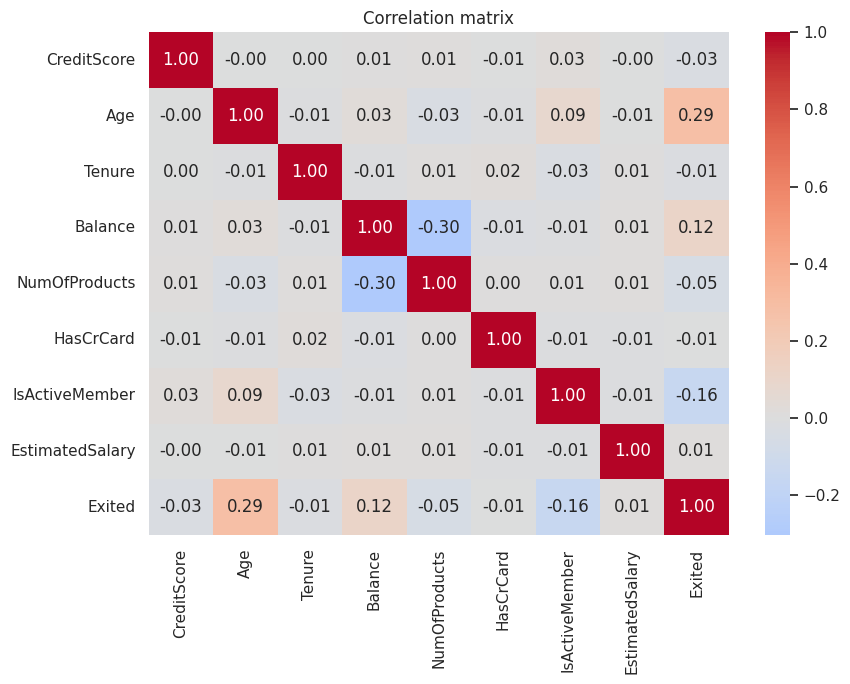

,Exited
Age,0.285
IsActiveMember,-0.156
Balance,0.119
NumOfProducts,-0.048
CreditScore,-0.027
Tenure,-0.014
EstimatedSalary,0.012
HasCrCard,-0.007


In [9]:
corr = df.select_dtypes(include="number").corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation matrix")
plt.tight_layout()
plt.show()

corr["Exited"].drop("Exited").sort_values(key=abs, ascending=False)

**Observations from the exploration**

- **Age:** churn rises sharply with age and peaks at about 56% for customers aged 50 to 60, against about 8% for customers under 30.
- **Geography:** German customers churn at about 32%, double the rate of French (16%) and Spanish (17%) customers.
- **Gender:** female customers churn more often than male customers (25% against 17%).
- **Activity:** inactive members churn at about 27%, against 14% for active members.
- **Products:** customers with two products rarely leave (8%), while those with three or four products almost always leave (83% and 100%). These two groups are small (266 and 60 customers).
- **Little signal:** tenure, credit card ownership and estimated salary show almost no relationship with churn.

## 5. Preprocessing and Train/Test Split

- Numeric columns are standardised so that large-valued columns such as `Balance` do not dominate Logistic Regression.
- `Geography` and `Gender` are one-hot encoded.
- The data is split 80/20 with stratification, so both parts keep the same churn rate.
- Every transformation sits inside a `Pipeline`, so it is fitted on training data only and no information leaks from the test set.

In [10]:
X = df.drop(columns="Exited")
y = df["Exited"]

categorical_cols = ["Geography", "Gender"]
numeric_cols = [c for c in X.columns if c not in categorical_cols]

preprocessor = ColumnTransformer(
    [
        ("num", StandardScaler(), numeric_cols),
        ("cat", OneHotEncoder(drop="first", sparse_output=False), categorical_cols),
    ]
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print("Train:", X_train.shape, "| churn rate:", round(y_train.mean(), 4))
print("Test: ", X_test.shape, "| churn rate:", round(y_test.mean(), 4))

Train: (8000, 10) | churn rate: 0.2037
Test:  (2000, 10) | churn rate: 0.2035


## 6. Train and Compare Models

Three algorithms are trained on the same split.

| Model | Notes |
| --- | --- |
| Logistic Regression | Simple, interpretable baseline. `class_weight="balanced"` gives the minority class more weight. |
| Random Forest | Many decision trees voting together. `class_weight="balanced"` is used here as well. |
| Gradient Boosting | Trees built one after another, each correcting the previous errors. |

In [11]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        min_samples_leaf=3,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}

pipelines = {
    name: Pipeline([("prep", preprocessor), ("model", model)])
    for name, model in models.items()
}

for pipe in pipelines.values():
    pipe.fit(X_train, y_train)

In [12]:
def evaluate(pipe, X_eval, y_eval, threshold=0.5):
    proba = pipe.predict_proba(X_eval)[:, 1]
    pred = (proba >= threshold).astype(int)
    return {
        "Accuracy": accuracy_score(y_eval, pred),
        "Precision": precision_score(y_eval, pred),
        "Recall": recall_score(y_eval, pred),
        "F1-score": f1_score(y_eval, pred),
        "ROC-AUC": roc_auc_score(y_eval, proba),
    }


baseline = pd.DataFrame(
    {name: evaluate(pipe, X_test, y_test) for name, pipe in pipelines.items()}
).T.sort_values("F1-score", ascending=False)

baseline

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Random Forest,0.857,0.672,0.580,0.623,0.860
Gradient Boosting,0.870,0.793,0.489,0.605,0.871
Logistic Regression,0.714,0.388,0.700,0.499,0.777


Precision, recall and F1-score above are for the **churn class**. Recall answers "of all customers who really left, how many did the model catch?", while precision answers "of all customers flagged as churners, how many really left?".

### 6.1 Confusion matrices and ROC curves

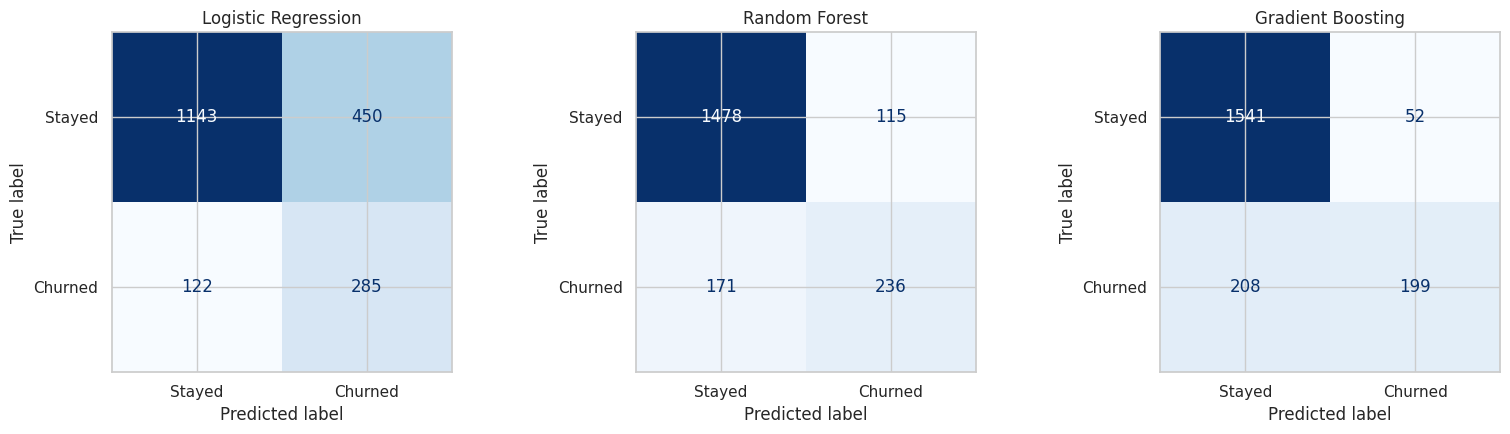

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, pipe) in zip(axes, pipelines.items()):
    ConfusionMatrixDisplay.from_estimator(
        pipe,
        X_test,
        y_test,
        display_labels=["Stayed", "Churned"],
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

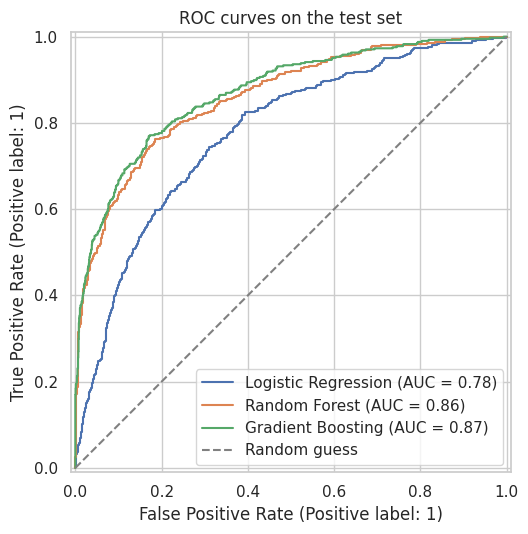

In [14]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for name, pipe in pipelines.items():
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Random guess")
ax.set_title("ROC curves on the test set")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 7. Cross-Validation

A single split can be lucky or unlucky. Stratified 5-fold cross-validation on the training data shows how stable each model is.

In [15]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

rows = {}
for name, pipe in pipelines.items():
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    rows[name] = {
        metric: f"{scores[f'test_{metric}'].mean():.3f} +/- {scores[f'test_{metric}'].std():.3f}"
        for metric in scoring
    }

pd.DataFrame(rows).T

,accuracy,precision,recall,f1,roc_auc
Logistic Regression,0.707 +/- 0.012,0.379 +/- 0.015,0.684 +/- 0.037,0.488 +/- 0.020,0.766 +/- 0.021
Random Forest,0.851 +/- 0.010,0.653 +/- 0.025,0.575 +/- 0.041,0.611 +/- 0.033,0.858 +/- 0.011
Gradient Boosting,0.863 +/- 0.010,0.772 +/- 0.032,0.464 +/- 0.036,0.580 +/- 0.036,0.865 +/- 0.010


## 8. Hyperparameter Tuning

Gradient Boosting is tuned with a grid search. The search is scored on **F1-score of the churn class**, which balances catching churners against false alarms.

In [16]:
param_grid = {
    "model__n_estimators": [100, 200, 300],
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__max_depth": [2, 3, 4],
    "model__subsample": [0.8, 1.0],
}

search = GridSearchCV(
    Pipeline(
        [
            ("prep", preprocessor),
            ("model", GradientBoostingClassifier(random_state=RANDOM_STATE)),
        ]
    ),
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
)
search.fit(X_train, y_train)

print("Best parameters:", search.best_params_)
print(f"Best cross-validated F1-score: {search.best_score_:.3f}")

Best parameters: {'model__learning_rate': 0.05, 'model__max_depth': 4, 'model__n_estimators': 300, 'model__subsample': 0.8}
Best cross-validated F1-score: 0.597


## 9. Decision Threshold

By default a customer is flagged as a churner when the predicted probability is at least 0.5. For imbalanced data a different threshold is often better.

The threshold is chosen using **out-of-fold predictions on the training data only**, so the test set stays untouched for the final evaluation.

Selected threshold: 0.264


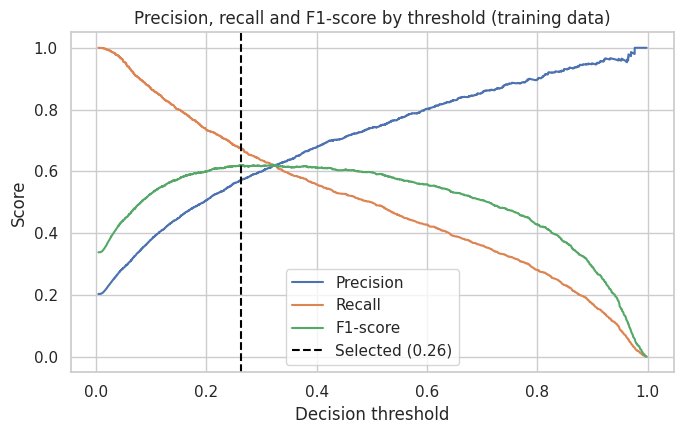

In [17]:
tuned = search.best_estimator_

oof_proba = cross_val_predict(
    tuned, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1
)[:, 1]

precision, recall, thresholds = precision_recall_curve(y_train, oof_proba)
f1_curve = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-12)
best_threshold = float(thresholds[np.argmax(f1_curve)])

print(f"Selected threshold: {best_threshold:.3f}")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(thresholds, precision[:-1], label="Precision")
ax.plot(thresholds, recall[:-1], label="Recall")
ax.plot(thresholds, f1_curve, label="F1-score")
ax.axvline(best_threshold, color="black", linestyle="--", label=f"Selected ({best_threshold:.2f})")
ax.set_xlabel("Decision threshold")
ax.set_ylabel("Score")
ax.set_title("Precision, recall and F1-score by threshold (training data)")
ax.legend()
plt.tight_layout()
plt.show()

## 10. Final Evaluation on the Test Set

In [18]:
final_model = tuned

proba_test = final_model.predict_proba(X_test)[:, 1]
pred_default = (proba_test >= 0.5).astype(int)
pred_tuned = (proba_test >= best_threshold).astype(int)

comparison = pd.DataFrame(
    {
        "Tuned GB, threshold 0.5": evaluate(final_model, X_test, y_test, 0.5),
        f"Tuned GB, threshold {best_threshold:.2f}": evaluate(
            final_model, X_test, y_test, best_threshold
        ),
    }
).T

pd.concat([baseline, comparison])

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Random Forest,0.857,0.672,0.580,0.623,0.860
Gradient Boosting,0.870,0.793,0.489,0.605,0.871
Logistic Regression,0.714,0.388,0.700,0.499,0.777
"Tuned GB, threshold 0.5",0.869,0.780,0.496,0.607,0.867
"Tuned GB, threshold 0.26",0.838,0.587,0.690,0.634,0.867


              precision    recall  f1-score   support

      Stayed       0.92      0.88      0.90      1593
     Churned       0.59      0.69      0.63       407

    accuracy                           0.84      2000
   macro avg       0.75      0.78      0.77      2000
weighted avg       0.85      0.84      0.84      2000



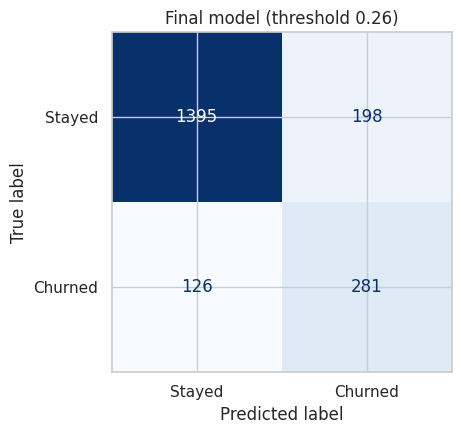

In [19]:
print(classification_report(y_test, pred_tuned, target_names=["Stayed", "Churned"]))

fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    pred_tuned,
    display_labels=["Stayed", "Churned"],
    cmap="Blues",
    colorbar=False,
    ax=ax,
)
ax.set_title(f"Final model (threshold {best_threshold:.2f})")
plt.tight_layout()
plt.show()

## 11. Feature Importance

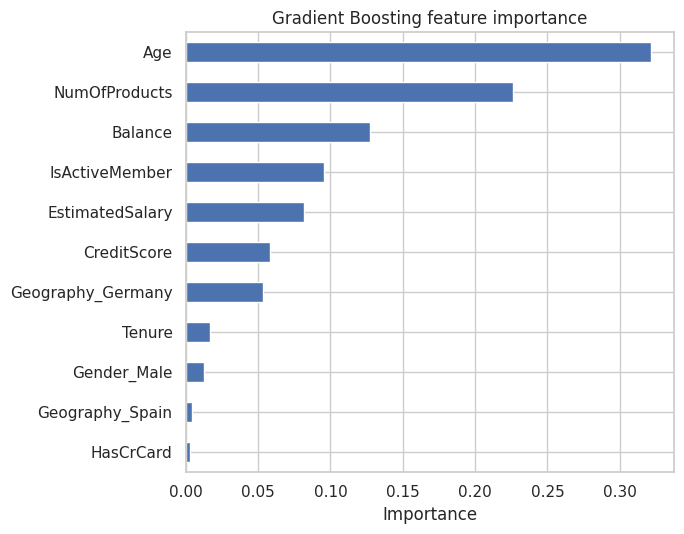

,0
Age,0.321
NumOfProducts,0.226
Balance,0.127
IsActiveMember,0.095
EstimatedSalary,0.082


In [20]:
feature_names = final_model.named_steps["prep"].get_feature_names_out()
feature_names = [n.split("__", 1)[1] for n in feature_names]
importances = final_model.named_steps["model"].feature_importances_

importance = (
    pd.Series(importances, index=feature_names).sort_values(ascending=True)
)

fig, ax = plt.subplots(figsize=(7, 5.5))
importance.plot.barh(ax=ax)
ax.set_xlabel("Importance")
ax.set_title("Gradient Boosting feature importance")
plt.tight_layout()
plt.show()

importance.sort_values(ascending=False).head(5)

Feature importance shows which columns the model relied on. It shows association, not cause, so it tells the business where to investigate rather than what is guaranteed to fix churn.

## 12. Save the Model and Predict for a New Customer

In [21]:
joblib.dump({"model": final_model, "threshold": best_threshold}, "churn_model.joblib")

saved = joblib.load("churn_model.joblib")
print("Saved and reloaded. Threshold:", round(saved["threshold"], 3))

Saved and reloaded. Threshold: 0.264


In [22]:
def predict_churn(customer, artefact=saved):
    frame = pd.DataFrame([customer])
    probability = artefact["model"].predict_proba(frame)[0, 1]
    label = "Likely to churn" if probability >= artefact["threshold"] else "Likely to stay"
    return probability, label


new_customer = {
    "CreditScore": 600,
    "Geography": "Germany",
    "Gender": "Female",
    "Age": 45,
    "Tenure": 3,
    "Balance": 120000.0,
    "NumOfProducts": 1,
    "HasCrCard": 1,
    "IsActiveMember": 0,
    "EstimatedSalary": 80000.0,
}

probability, label = predict_churn(new_customer)
print(f"Churn probability: {probability:.1%}")
print("Prediction:", label)

Churn probability: 77.4%
Prediction: Likely to churn


## 13. Conclusion

**Results**

- Three models were compared on the same stratified split. Logistic Regression was the weakest (ROC-AUC 0.78). Random Forest and Gradient Boosting were clearly stronger (ROC-AUC 0.86 and 0.87).
- At the default 0.5 threshold, Gradient Boosting reached 87% accuracy but caught only about half of the churners (recall 0.49). This is the accuracy trap of imbalanced data.
- Choosing the decision threshold on training data (about 0.29) raised recall of the tuned Gradient Boosting model from 0.49 to 0.65 at the cost of some precision. On the unseen test set it reached accuracy 0.84, precision 0.60, recall 0.65, F1-score 0.62 and ROC-AUC 0.87.
- Random Forest reached a similar F1-score (0.62), so the tuned Gradient Boosting model and Random Forest are close. Tuning gave only a small gain over the default Gradient Boosting settings.

**Drivers of churn**

Age, number of products, balance and activity status are the most important features. Older customers, customers with one or three or more products, German customers and inactive members are the highest-risk groups.

**Business use**

- Rank customers by predicted churn probability and focus retention offers on the highest-risk customers first.
- Review the product mix, since customers with three or four products almost always leave.
- Re-engage inactive members and look into why German customers churn at twice the rate of the others.

**Limitations and next steps**

- The test set has only 407 churners, so the scores carry some uncertainty.
- Features such as complaints, service calls or transaction trends are not in this dataset and would likely improve predictions.
- Further options are interaction features, XGBoost or LightGBM, and costing the two error types to select the threshold by business value.